In [3]:
import h5py
import numpy as np
from tensorflow import keras
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

In [4]:
train_file = "fetch/train_data.hdf5"

with h5py.File(train_file, "r") as f:
    print("Top-level keys (groups or datasets):")
    for key in f.keys():
        print(" -", key)
        if isinstance(f[key], h5py.Group):
            print("   Contains datasets:", list(f[key].keys()))
        elif isinstance(f[key], h5py.Dataset):
            print("   Shape:", f[key].shape)
            print("   Dtype:", f[key].dtype)

Top-level keys (groups or datasets):
 - data_dm_time
   Shape: (40000, 256, 256, 1)
   Dtype: float32
 - data_freq_time
   Shape: (40000, 256, 256, 1)
   Dtype: float32
 - data_labels
   Shape: (40000,)
   Dtype: bool


In [5]:
from tensorflow.image import resize

# Load training data
with h5py.File(train_file, "r") as f:
    # X_train_ft = np.array(f["data_freq_time"], dtype=np.float32)
    X_train_dt = np.array(f["data_dm_time"], dtype=np.float32)
    y_train = np.array(f["data_labels"], dtype=int)

# Check the shape before resizing
print("Original X_train_dt shape:", X_train_dt.shape)
print("y_train shape:", y_train.shape)

# Resize each image from (256, 256, 1) to (64, 64, 1)
X_train = np.array([resize(img, (64, 64)) for img in X_train_dt])

# Ensure the reshaped X_train matches the number of labels in y_train
assert X_train.shape[0] == y_train.shape[0], "Mismatch between X_train and y_train samples"

# One-hot encode the labels
y_train = to_categorical(y_train, num_classes=2)

Original X_train_dt shape: (40000, 256, 256, 1)
y_train shape: (40000,)


In [6]:
test_file = "fetch/test_data.hdf5"

with h5py.File(test_file, "r") as f:
    print("Top-level keys (groups or datasets):")
    for key in f.keys():
        print(" -", key)
        # Check what’s inside each key
        if isinstance(f[key], h5py.Group):
            print("   Contains datasets:", list(f[key].keys()))
        elif isinstance(f[key], h5py.Dataset):
            print("   Shape:", f[key].shape)
            print("   Dtype:", f[key].dtype)

Top-level keys (groups or datasets):
 - data_dm_time
   Shape: (13983, 256, 256, 1)
   Dtype: float32
 - data_freq_time
   Shape: (13983, 256, 256, 1)
   Dtype: float32
 - data_labels
   Shape: (13983,)
   Dtype: bool


In [7]:
# Load test data
with h5py.File(test_file, "r") as f:
    # X_ft = np.array(f["data_freq_time"], dtype=np.float32)
    X_dt = np.array(f["data_dm_time"], dtype=np.float32)
    y_true = np.array(f["data_labels"], dtype=int)  # bool to int

# Check the shape before resizing
print("Original X_test_dt shape:", X_dt.shape)
print("y_true shape:", y_true.shape)

# Resize each image from (256, 256, 1) to (64, 64, 1)
X_test = np.array([resize(img, (64, 64)) for img in X_dt])

# One-hot encode the test labels
y_true = to_categorical(y_true, num_classes=2)

# Ensure the reshaped X_test matches the number of test labels
assert X_test.shape[0] == y_true.shape[0], "Mismatch between X_test and y_true samples"

Original X_test_dt shape: (13983, 256, 256, 1)
y_true shape: (13983,)


In [ ]:

# Create fixed validation set
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, 
    y_train,
    test_size=0.2,  # 20% validation split
    random_state=42,  # Fixed seed for reproducibility
    stratify=np.argmax(y_train, axis=1)  # Uses keras' to_categorical encoding to maintain class distribution
)

In [9]:
# Now X_train, X_test, y_train, y_true should all be correctly shaped
print("Final shapes:")
print("X_train_resized shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test_resized shape:", X_test.shape)
print("y_true shape:", y_true.shape)

print()
# Frozen dataset
print('Final Shapes (frozen dataset):')
print("X_train_final shape:", X_train_final.shape)
print("y_train_final shape:", y_train_final.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

Final shapes:
X_train_resized shape: (40000, 64, 64, 1)
y_train shape: (40000, 2)
X_test_resized shape: (13983, 64, 64, 1)
y_true shape: (13983, 2)

Final Shapes (frozen dataset):
X_train_final shape: (32000, 64, 64, 1)
y_train_final shape: (32000, 2)
X_val shape: (8000, 64, 64, 1)
y_val shape: (8000, 2)


In [10]:
def create_simple_cnn(input_shape):
    model = Sequential()
    model.add(Conv2D(2, (3, 3), activation='relu', input_shape=input_shape))
    model.add(Dropout(0.5))
    model.add(Conv2D(2, (3, 3), activation='relu'))
    model.add(Flatten())
    model.add(Dense(2, activation='softmax'))  # Output layer for 2 classes (RFI, FRB)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Define the input shape (assuming X_ft has shape [samples, height, width, 1])
input_shape = (X_train.shape[1], X_train.shape[2], 1)

# Create the model
model = create_simple_cnn(input_shape)

c:\Users\tobys\miniconda3\envs\frb\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.fit(
    X_train_final,
    y_train_final,
    batch_size=32,
    epochs=10,
    validation_data=(X_val, y_val)  # Use fixed validation set
)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9348 - loss: 0.1605 - val_accuracy: 0.9035 - val_loss: 0.3018
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9730 - loss: 0.0752 - val_accuracy: 0.9224 - val_loss: 0.2238
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9792 - loss: 0.0614 - val_accuracy: 0.9171 - val_loss: 0.2452
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9823 - loss: 0.0510 - val_accuracy: 0.9373 - val_loss: 0.1770
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9861 - loss: 0.0432 - val_accuracy: 0.9619 - val_loss: 0.1051
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9875 - loss: 0.0374 - val_accuracy: 0.9571 - val_loss: 0.1256
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9898 - loss: 0.0310 - val_accuracy: 0.9671 - val_loss: 0.0938
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9889 - loss: 0.0330 - 

437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 957us/step
Test Accuracy: 0.9520131588357291
Confusion matrix:
 [[7314    5]
 [ 666 5998]]
              precision    recall  f1-score   support

         RFI       0.92      1.00      0.96      7319
         FRB       1.00      0.90      0.95      6664

    accuracy                           0.95     13983
   macro avg       0.96      0.95      0.95     13983
weighted avg       0.96      0.95      0.95     13983

AUC (FRB as positive): 0.9946698654868422


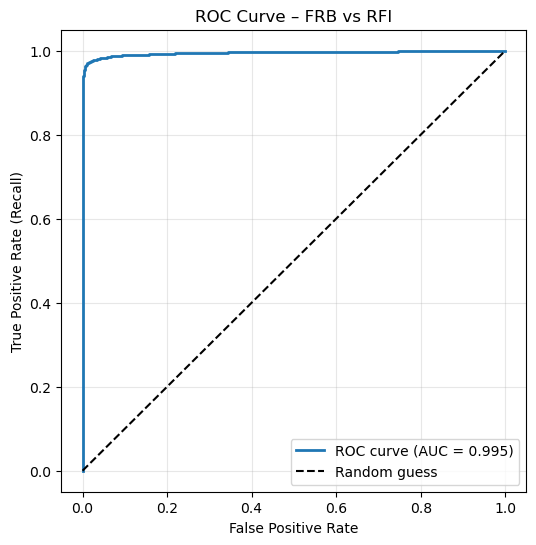

In [12]:
# Make predictions
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)  # Predicted classes

# Compute accuracy
acc = accuracy_score(np.argmax(y_true, axis=1), y_pred)  # Use argmax on y_true for comparison
print("Test Accuracy:", acc)

# Confusion Matrix and Classification Report
cm = confusion_matrix(np.argmax(y_true, axis=1), y_pred)
report = classification_report(np.argmax(y_true, axis=1), y_pred, target_names=["RFI", "FRB"])
print("Confusion matrix:\n", cm)
print(report)

# Compute ROC AUC for FRB (class 1 as positive)
p_frb = y_prob[:, 1]  # probability of class 'FRB'
auc = roc_auc_score(np.argmax(y_true, axis=1), p_frb)
print("AUC (FRB as positive):", auc)

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(np.argmax(y_true, axis=1), p_frb)

# Plot ROC curve
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})", linewidth=2)
plt.plot([0,1], [0,1], 'k--', label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve – FRB vs RFI")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 2)      │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 2)      │            38 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │        14,402 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,382 (169.46 KB)

 Trainable params: 14,460 (56.48 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 28,922 (112.98 KB)